In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

raiz = Path.cwd().parent

archivos = [
    raiz / "data/raw/shots_2024.parquet",
    raiz / "data/raw/shots_2025.parquet",
    raiz / "data/raw/shots_2026.parquet"
]

df = pd.concat(
    [pd.read_parquet(archivo) for archivo in archivos],
    ignore_index=True
)

print("NBA SHOT IQ - EXPLORACION INICIAL")
print("Registros:", len(df))
print("Columnas:", len(df.columns))
print("Temporadas:", df["season"].unique())

display(df.head())

NBA SHOT IQ - EXPLORACION INICIAL
Registros: 703805
Columnas: 19
Temporadas: [2024 2025 2026]


,game_id,season,season_type_id,period,clock,team_id,team_tricode,person_id,player_name,action_type,sub_type,shot_result,shot_value,shot_distance,x_legacy,y_legacy,description,score_home,score_away
0,0022300001,2024,2,1,PT11M41.00S,1610612754,IND,1626167,Turner,Made Shot,Cutting Dunk Shot,Made,2,2,2,21,Turner 2' Cutting Dunk Shot (2 PTS) (Haliburto...,2,0
1,0022300001,2024,2,1,PT11M23.00S,1610612739,CLE,1630596,Mobley,Missed Shot,Turnaround Jump Shot,Missed,2,8,59,53,MISS Mobley 8' Turnaround Jump Shot,,
2,0022300001,2024,2,1,PT11M15.00S,1610612754,IND,1628971,Brown,Missed Shot,Running Layup Shot,Missed,2,2,13,18,MISS Brown 2' Running Layup,,
3,0022300001,2024,2,1,PT11M09.00S,1610612754,IND,1631097,Mathurin,Made Shot,Jump Shot,Made,3,28,151,237,Mathurin 28' 3PT Jump Shot (3 PTS) (Brown 1 AST),5,0
4,0022300001,2024,2,1,PT10M56.00S,1610612739,CLE,1628378,Mitchell,Made Shot,Driving Dunk Shot,Made,2,2,-20,1,Mitchell 2' Driving Dunk (2 PTS) (Garland 1 AST),5,2


In [2]:
# NBA SHOT IQ - Calidad inicial de los datos

print("1. DIMENSIONES DEL CONJUNTO")
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

print("\n2. TIPOS DE DATOS")
display(df.dtypes.to_frame(name="Tipo de dato"))

print("\n3. VALORES FALTANTES")
faltantes = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "Cadenas vacias": df.select_dtypes(include="object")
        .apply(lambda columna: columna.astype(str).str.strip().eq("").sum())
        .reindex(df.columns, fill_value=0)
})

faltantes["Total detectado"] = (
    faltantes["Nulos"] + faltantes["Cadenas vacias"]
)

faltantes["Porcentaje"] = (
    faltantes["Total detectado"] / len(df) * 100
).round(2)

display(faltantes)

print("\n4. DUPLICADOS EXACTOS")
print("Total:", df.duplicated().sum())

print("\n5. REGISTROS POR TEMPORADA")
display(
    df.groupby("season")
      .size()
      .reset_index(name="Registros")
)

1. DIMENSIONES DEL CONJUNTO
Filas: 703805
Columnas: 19

2. TIPOS DE DATOS


,Tipo de dato
game_id,str
season,int32
season_type_id,str
period,int64
clock,str
team_id,int64
team_tricode,str
person_id,int64
player_name,str
action_type,str



3. VALORES FALTANTES


C:\Users\inici\AppData\Local\Temp\ipykernel_19676\213829027.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  "Cadenas vacias": df.select_dtypes(include="object")


,Nulos,Cadenas vacias,Total detectado,Porcentaje
game_id,0,0,0,0.00
season,0,0,0,0.00
season_type_id,0,0,0,0.00
period,0,0,0,0.00
clock,0,0,0,0.00
team_id,0,0,0,0.00
team_tricode,0,0,0,0.00
person_id,0,0,0,0.00
player_name,0,0,0,0.00
action_type,0,0,0,0.00



4. DUPLICADOS EXACTOS
Total: 24

5. REGISTROS POR TEMPORADA


,season,Registros
0,2024,233789
1,2025,235140
2,2026,234876


In [3]:
# NBA SHOT IQ - Estadisticas descriptivas

print("1. RESUMEN DE VARIABLES NUMERICAS")
display(
    df[[
        "period",
        "shot_value",
        "shot_distance",
        "x_legacy",
        "y_legacy"
    ]].describe().round(2)
)

print("\n2. RESULTADOS DE LOS TIROS")
resultados = df["shot_result"].value_counts()
display(resultados.to_frame(name="Cantidad"))

print("\n3. TIPOS DE TIRO")
display(
    df["shot_value"]
    .value_counts()
    .sort_index()
    .to_frame(name="Cantidad")
)

print("\n4. EFECTIVIDAD GENERAL")
efectividad = df["shot_result"].eq("Made").mean() * 100
print(f"Porcentaje de tiros encestados: {efectividad:.2f}%")

print("\n5. EFECTIVIDAD POR TEMPORADA")
efectividad_temporada = (
    df.assign(encestado=df["shot_result"].eq("Made"))
      .groupby("season")["encestado"]
      .agg(["count", "mean"])
)

efectividad_temporada["mean"] *= 100
efectividad_temporada.columns = [
    "Intentos",
    "Efectividad (%)"
]

display(efectividad_temporada.round(2))

1. RESUMEN DE VARIABLES NUMERICAS


,period,shot_value,shot_distance,x_legacy,y_legacy
count,703805.00,703805.00,703805.00,703805.00,703805.00
mean,2.48,2.41,14.28,-2.21,95.76
std,1.13,0.49,10.60,115.88,94.95
min,1.00,2.00,0.00,-250.00,-52.00
25%,1.00,2.00,3.00,-51.00,14.00
50%,2.00,2.00,13.00,0.00,56.00
75%,3.00,3.00,25.00,47.00,183.00
max,6.00,3.00,87.00,250.00,856.00



2. RESULTADOS DE LOS TIROS


,Cantidad
shot_result,
Missed,373106
Made,330699



3. TIPOS DE TIRO


,Cantidad
shot_value,
2,415305
3,288500



4. EFECTIVIDAD GENERAL
Porcentaje de tiros encestados: 46.99%

5. EFECTIVIDAD POR TEMPORADA


,Intentos,Efectividad (%)
season,,
2024,233789,47.35
2025,235140,46.64
2026,234876,46.98


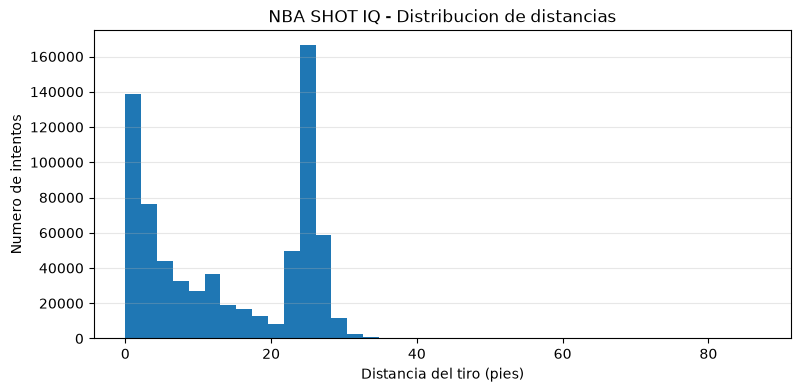

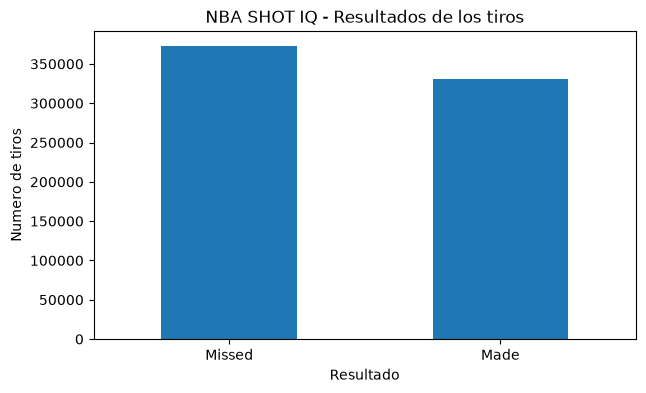

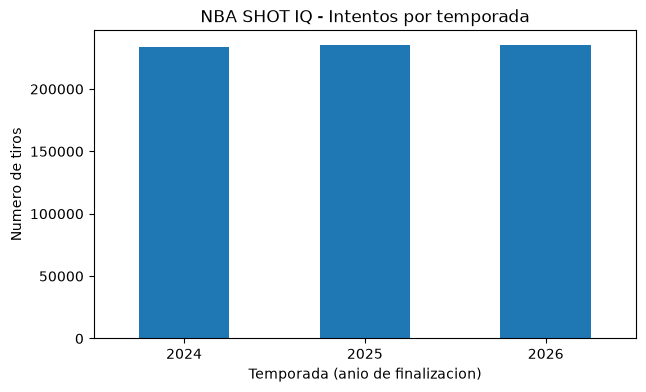

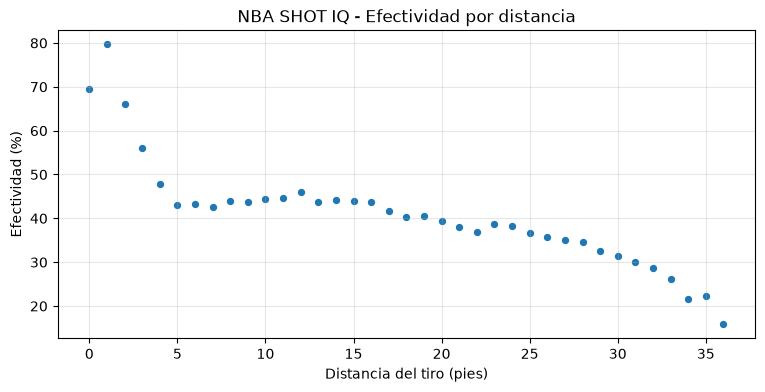

In [4]:
import matplotlib.pyplot as plt

# 1. Distribucion de distancias
plt.figure(figsize=(9, 4))
plt.hist(df["shot_distance"].dropna(), bins=40)
plt.title("NBA SHOT IQ - Distribucion de distancias")
plt.xlabel("Distancia del tiro (pies)")
plt.ylabel("Numero de intentos")
plt.grid(axis="y", alpha=0.3)
plt.show()

# 2. Tiros encestados y fallados
plt.figure(figsize=(7, 4))
df["shot_result"].value_counts().plot(kind="bar")
plt.title("NBA SHOT IQ - Resultados de los tiros")
plt.xlabel("Resultado")
plt.ylabel("Numero de tiros")
plt.xticks(rotation=0)
plt.show()

# 3. Intentos por temporada
plt.figure(figsize=(7, 4))
df["season"].value_counts().sort_index().plot(kind="bar")
plt.title("NBA SHOT IQ - Intentos por temporada")
plt.xlabel("Temporada (anio de finalizacion)")
plt.ylabel("Numero de tiros")
plt.xticks(rotation=0)
plt.show()

# 4. Efectividad por distancia
df_grafica = df.copy()
df_grafica["encestado"] = df_grafica["shot_result"].eq("Made")

efectividad_distancia = (
    df_grafica.groupby("shot_distance")["encestado"]
    .agg(["mean", "count"])
)

# Evitar distancias con muy pocos intentos
efectividad_distancia = efectividad_distancia[
    efectividad_distancia["count"] >= 100
]

plt.figure(figsize=(9, 4))
plt.scatter(
    efectividad_distancia.index,
    efectividad_distancia["mean"] * 100,
    s=18
)
plt.title("NBA SHOT IQ - Efectividad por distancia")
plt.xlabel("Distancia del tiro (pies)")
plt.ylabel("Efectividad (%)")
plt.grid(alpha=0.3)
plt.show()

## 6. Observaciones y conclusiones de la exploración

### Hallazgos principales

- Se analizaron 703,805 registros de intentos de tiro correspondientes a tres temporadas de la NBA.
- La efectividad general fue de aproximadamente 46.99 %.
- Los intentos se concentran principalmente cerca de la canasta y en distancias asociadas con tiros de tres puntos.
- La efectividad tiende a disminuir conforme aumenta la distancia de lanzamiento.
- Las tres temporadas presentan cantidades similares de intentos de tiro.

### Problemas de calidad identificados

- Se encontraron 24 registros duplicados exactos en los datos originales.
- Las columnas `score_home` y `score_away` presentan 373,106 cadenas vacías, asociadas con tiros fallados. Es necesario tratarlas correctamente durante el procesamiento.
- Los datos incluyen tiros de distintas distancias y algunos valores extremos que requieren revisión.
- La eliminación de duplicados debe realizarse con cuidado, porque no existe un identificador único de intento de tiro.

### Limitaciones

- La exploración es descriptiva y no demuestra relaciones causales.
- Los marcadores disponibles no permiten identificar directamente el marcador previo a cada lanzamiento.
- Para analizar las rachas de anotación y las situaciones clutch se necesitarán transformaciones adicionales.

### Preguntas pendientes

1. ¿Qué zonas de la cancha presentan mayor efectividad?
2. ¿Existen diferencias importantes entre equipos y jugadores?
3. ¿Las rachas de tiros encestados se relacionan con una mayor probabilidad de encestar el siguiente tiro?
4. ¿Cómo cambia la efectividad en los momentos finales de partidos cerrados?

### Siguiente etapa

En el segundo parcial se realizará la limpieza, transformación y validación de los datos, conservando los archivos originales y generando conjuntos preparados para su análisis.